In [10]:
from utils.library import *
from utils.download import *
from utils.metrics import split_temporal
from utils.stock_config import *
from models.arima import *
from models.xgboost import run_xgbooster
from models.lstm import run_lstm, run_lstm_30
from utils.plots import plot_forecast
from models.shap import explain_variables


In [11]:
pretro_csv = 'data/petro.csv'

if not os.path.exists(pretro_csv):
    petr4_dataset = load_stock(STOCKS["petro"], "petro", force=True)
    petr4_dataset.head(10)

petr4_dataset = pd.read_csv(pretro_csv)

In [12]:
print(petr4_dataset.isna().sum())

date            0
petro_close     0
petro_high      0
petro_low       0
petro_open      0
petro_volume    0
ibovespa        0
vix             0
selic_daily     0
selic_goal      0
ipca            0
fx_usd          0
gdp             0
unemployment    0
dtype: int64


In [13]:
petr4_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 3439 entries, 0 to 3438
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          3439 non-null   str    
 1   petro_close   3439 non-null   float64
 2   petro_high    3439 non-null   float64
 3   petro_low     3439 non-null   float64
 4   petro_open    3439 non-null   float64
 5   petro_volume  3439 non-null   int64  
 6   ibovespa      3439 non-null   float64
 7   vix           3439 non-null   float64
 8   selic_daily   3439 non-null   float64
 9   selic_goal    3439 non-null   float64
 10  ipca          3439 non-null   float64
 11  fx_usd        3439 non-null   float64
 12  gdp           3439 non-null   float64
 13  unemployment  3439 non-null   float64
dtypes: float64(12), int64(1), str(1)
memory usage: 376.3 KB


## ARIMA

In [ ]:
train_petro, test_petro = split_temporal(petr4_dataset)
res_petro = run_arima(train_petro, test_petro, "petro")

--- Identificando ordem do ARIMA para PETRO ---
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-1722.106, Time=1.37 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-1693.732, Time=0.10 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-1692.523, Time=0.08 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-1692.524, Time=0.09 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-1695.136, Time=0.06 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-1694.017, Time=0.71 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=-1688.526, Time=0.24 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=-1694.084, Time=1.35 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=-1698.157, Time=1.49 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-1690.453, Time=0.17 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=-1689.855, Time=0.42 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=-1696.596, Time=0.69 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=-1694.888, Time=1.43 sec
 ARIMA(2,1,2)(0,0,0)[0]             : 

c:\TCC\venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\TCC\venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


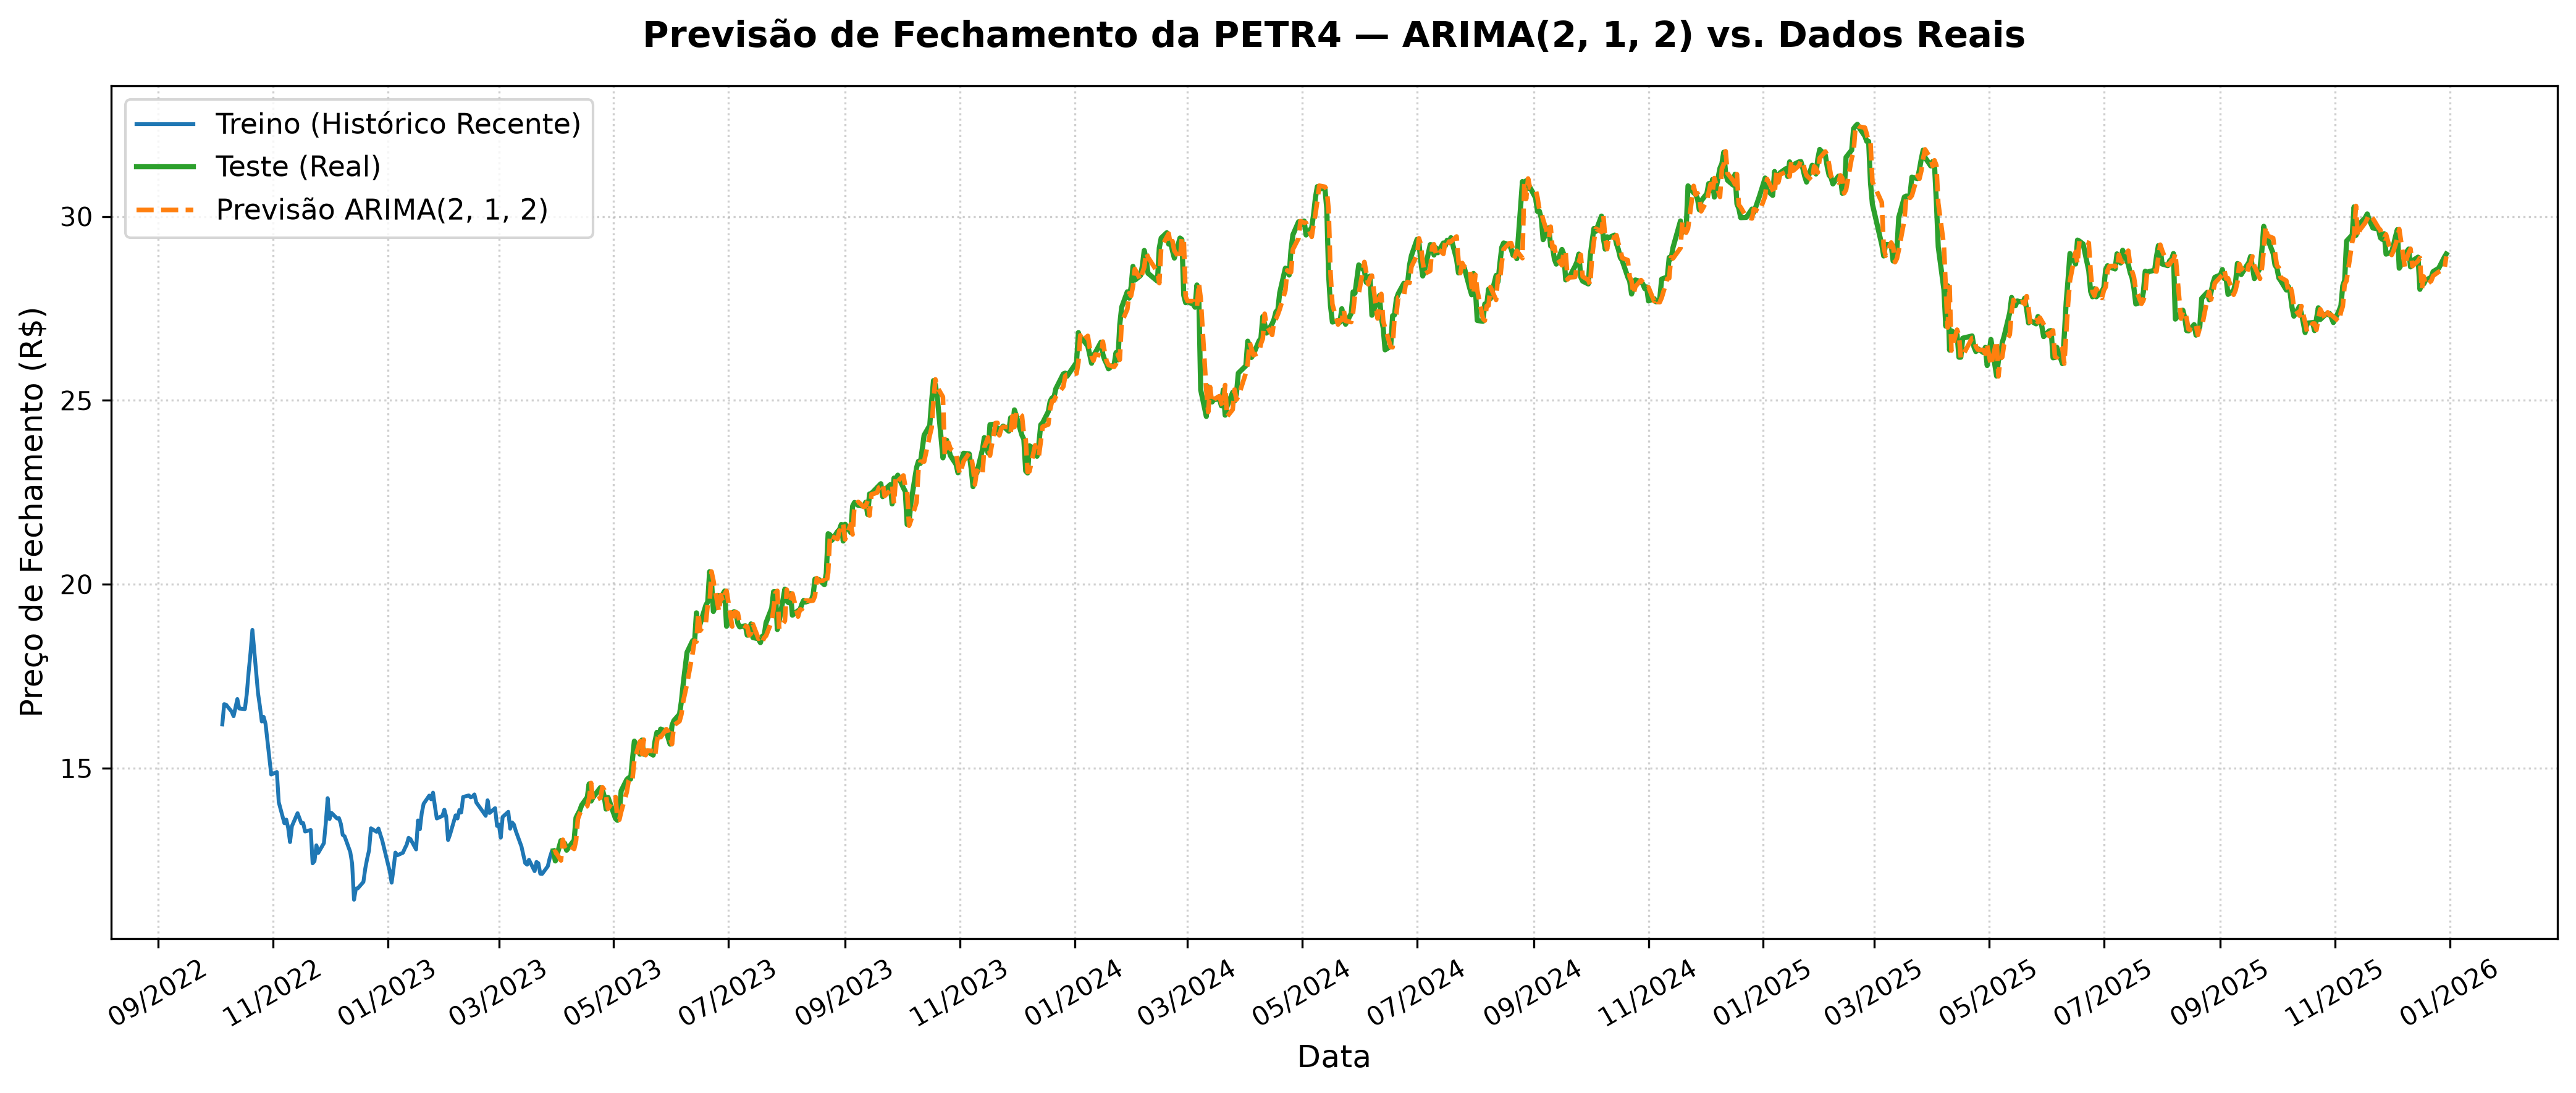

In [ ]:
plot_forecast(
    train_petro, test_petro,
    predictions=res_petro["predictions"],
    stock_name="petro",
    model_name=f"ARIMA{res_petro['order']}",
    ticker_label="PETR4",
)

## XGBooster

--- XGBoost PETRO: 37 features, 2748 treino / 688 teste ---
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Melhores hiperparâmetros: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Melhor RMSE médio (validação): 1.2751
XGBoost petro          RMSE: 10.3766 | MAE: 9.5959 | MAPE: 34.51% | Acurácia direcional: 45.93%
Naive petro            RMSE: 0.4173 | MAE: 0.2991 | MAPE: 1.18% | Acurácia direcional: n/a
p-valor (teste binomial, acurácia direcional): 0.0359


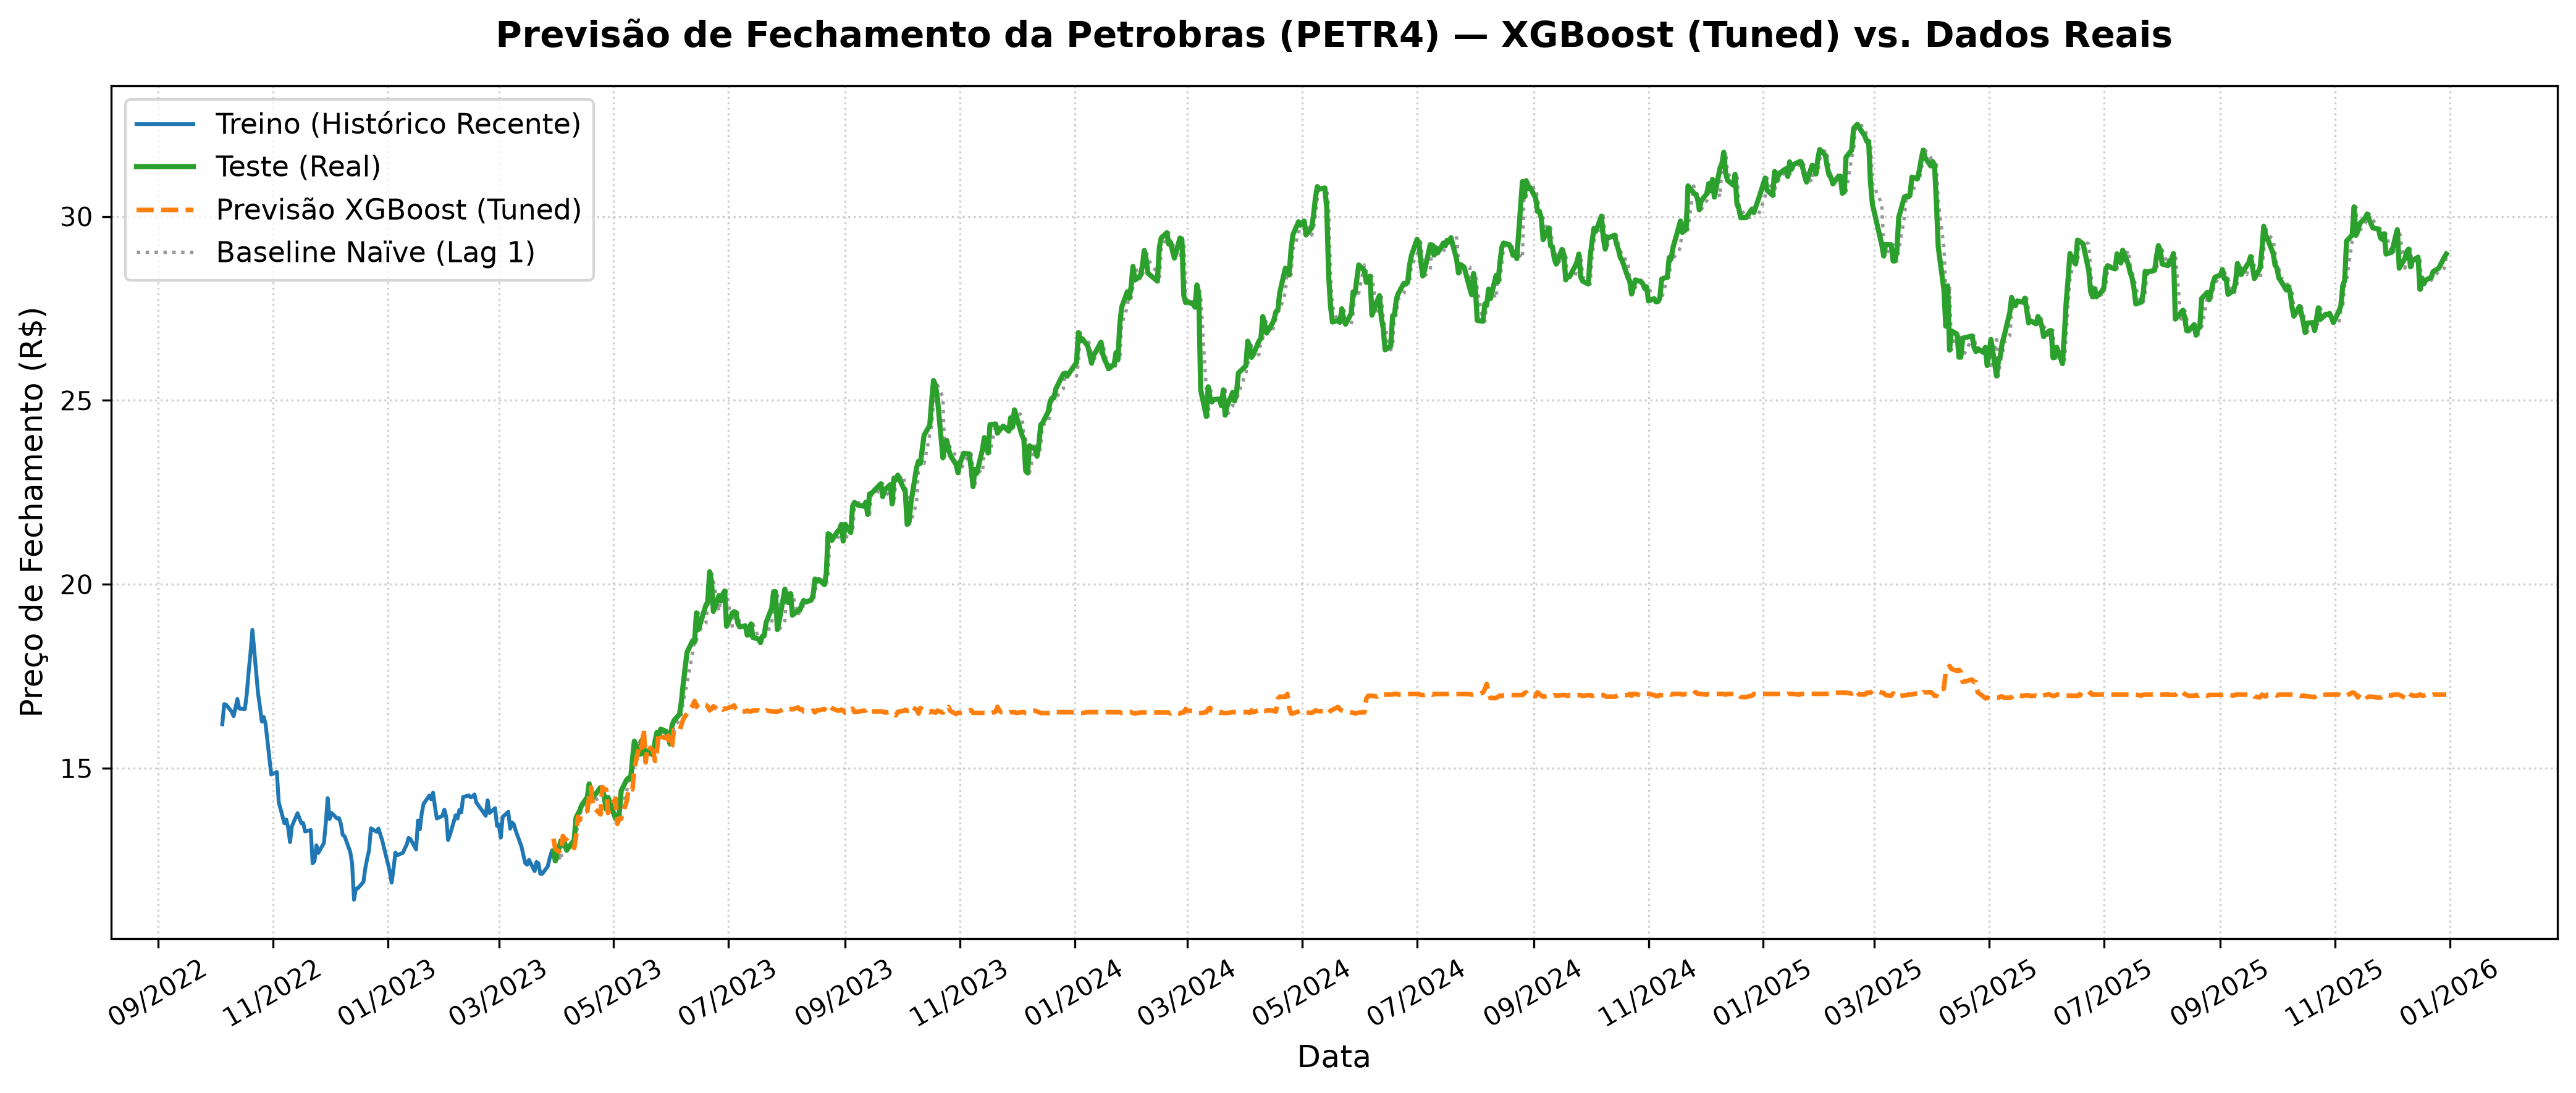

In [ ]:
res_xgbooster = run_xgbooster(train_petro, test_petro, "petro")
plot_forecast(
    train_petro, test_petro,
    predictions=res_xgbooster["predictions"],
    stock_name="petro",
    model_name="XGBoost (Tuned)",
    ticker_label="PETR4",
    company_name="Petrobras",
    baseline=res_xgbooster["ontem"],        # baseline naive (preço de ontem)
)

In [ ]:
res_lstm = run_lstm(train_petro, test_petro, "petro", max_epochs=10)
plot_forecast(train_petro, test_petro, res_lstm["predictions"], "petro",
              model_name="LSTM (Tuned)", ticker_label="PETR4",
              company_name="Petrobras", baseline=res_lstm["ontem"])

In [ ]:
res_lstm_30 = run_lstm_30(train_petro, test_petro, "petro", res_lstm["best_params"])

In [ ]:
res_30 = run_lstm_30(train_petro, test_petro, "petro", res_lstm["best_params"])

res_30["metricas"]                       # RMSE / MAE / MAPE por origem, com o RMSE do naive
res_30["metricas"].mean(numeric_only=True)

plot_forecast_30(res_30, train_petro, test_petro, "petro", origem="2025-03-31")   # backtest com preço real
plot_forecast_30(res_30, train_petro, test_petro, "petro")                        # previsão futura


Epoch 1/100
16/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2468

c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1481.)
  outputs, h_n, c_n = torch._VF.lstm(


36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1948 - val_loss: 1.1259
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0460 - val_loss: 0.4575
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0159 - val_loss: 0.2972
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0113 - val_loss: 0.3031
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0094 - val_loss: 0.3094
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0087 - val_loss: 0.2871
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0085 - val_loss: 0.3077
Epoch 8/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0082 - val_loss: 0.3038
Epoch 9/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0080 - val_loss: 0.3001
Epoch 10/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0079 - val_loss: 0.3070
Epoch 11/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0079 - val_loss: 0.3089


TypeError: unsupported operand type(s) for +: 'int' and 'Timedelta'

In [ ]:
tab_petro = explain_variables(res_petro)
tab_petro.head(10)

InvalidModelError: Model type not yet supported by TreeExplainer: <class 'statsmodels.tsa.arima.model.ARIMAResultsWrapper'>

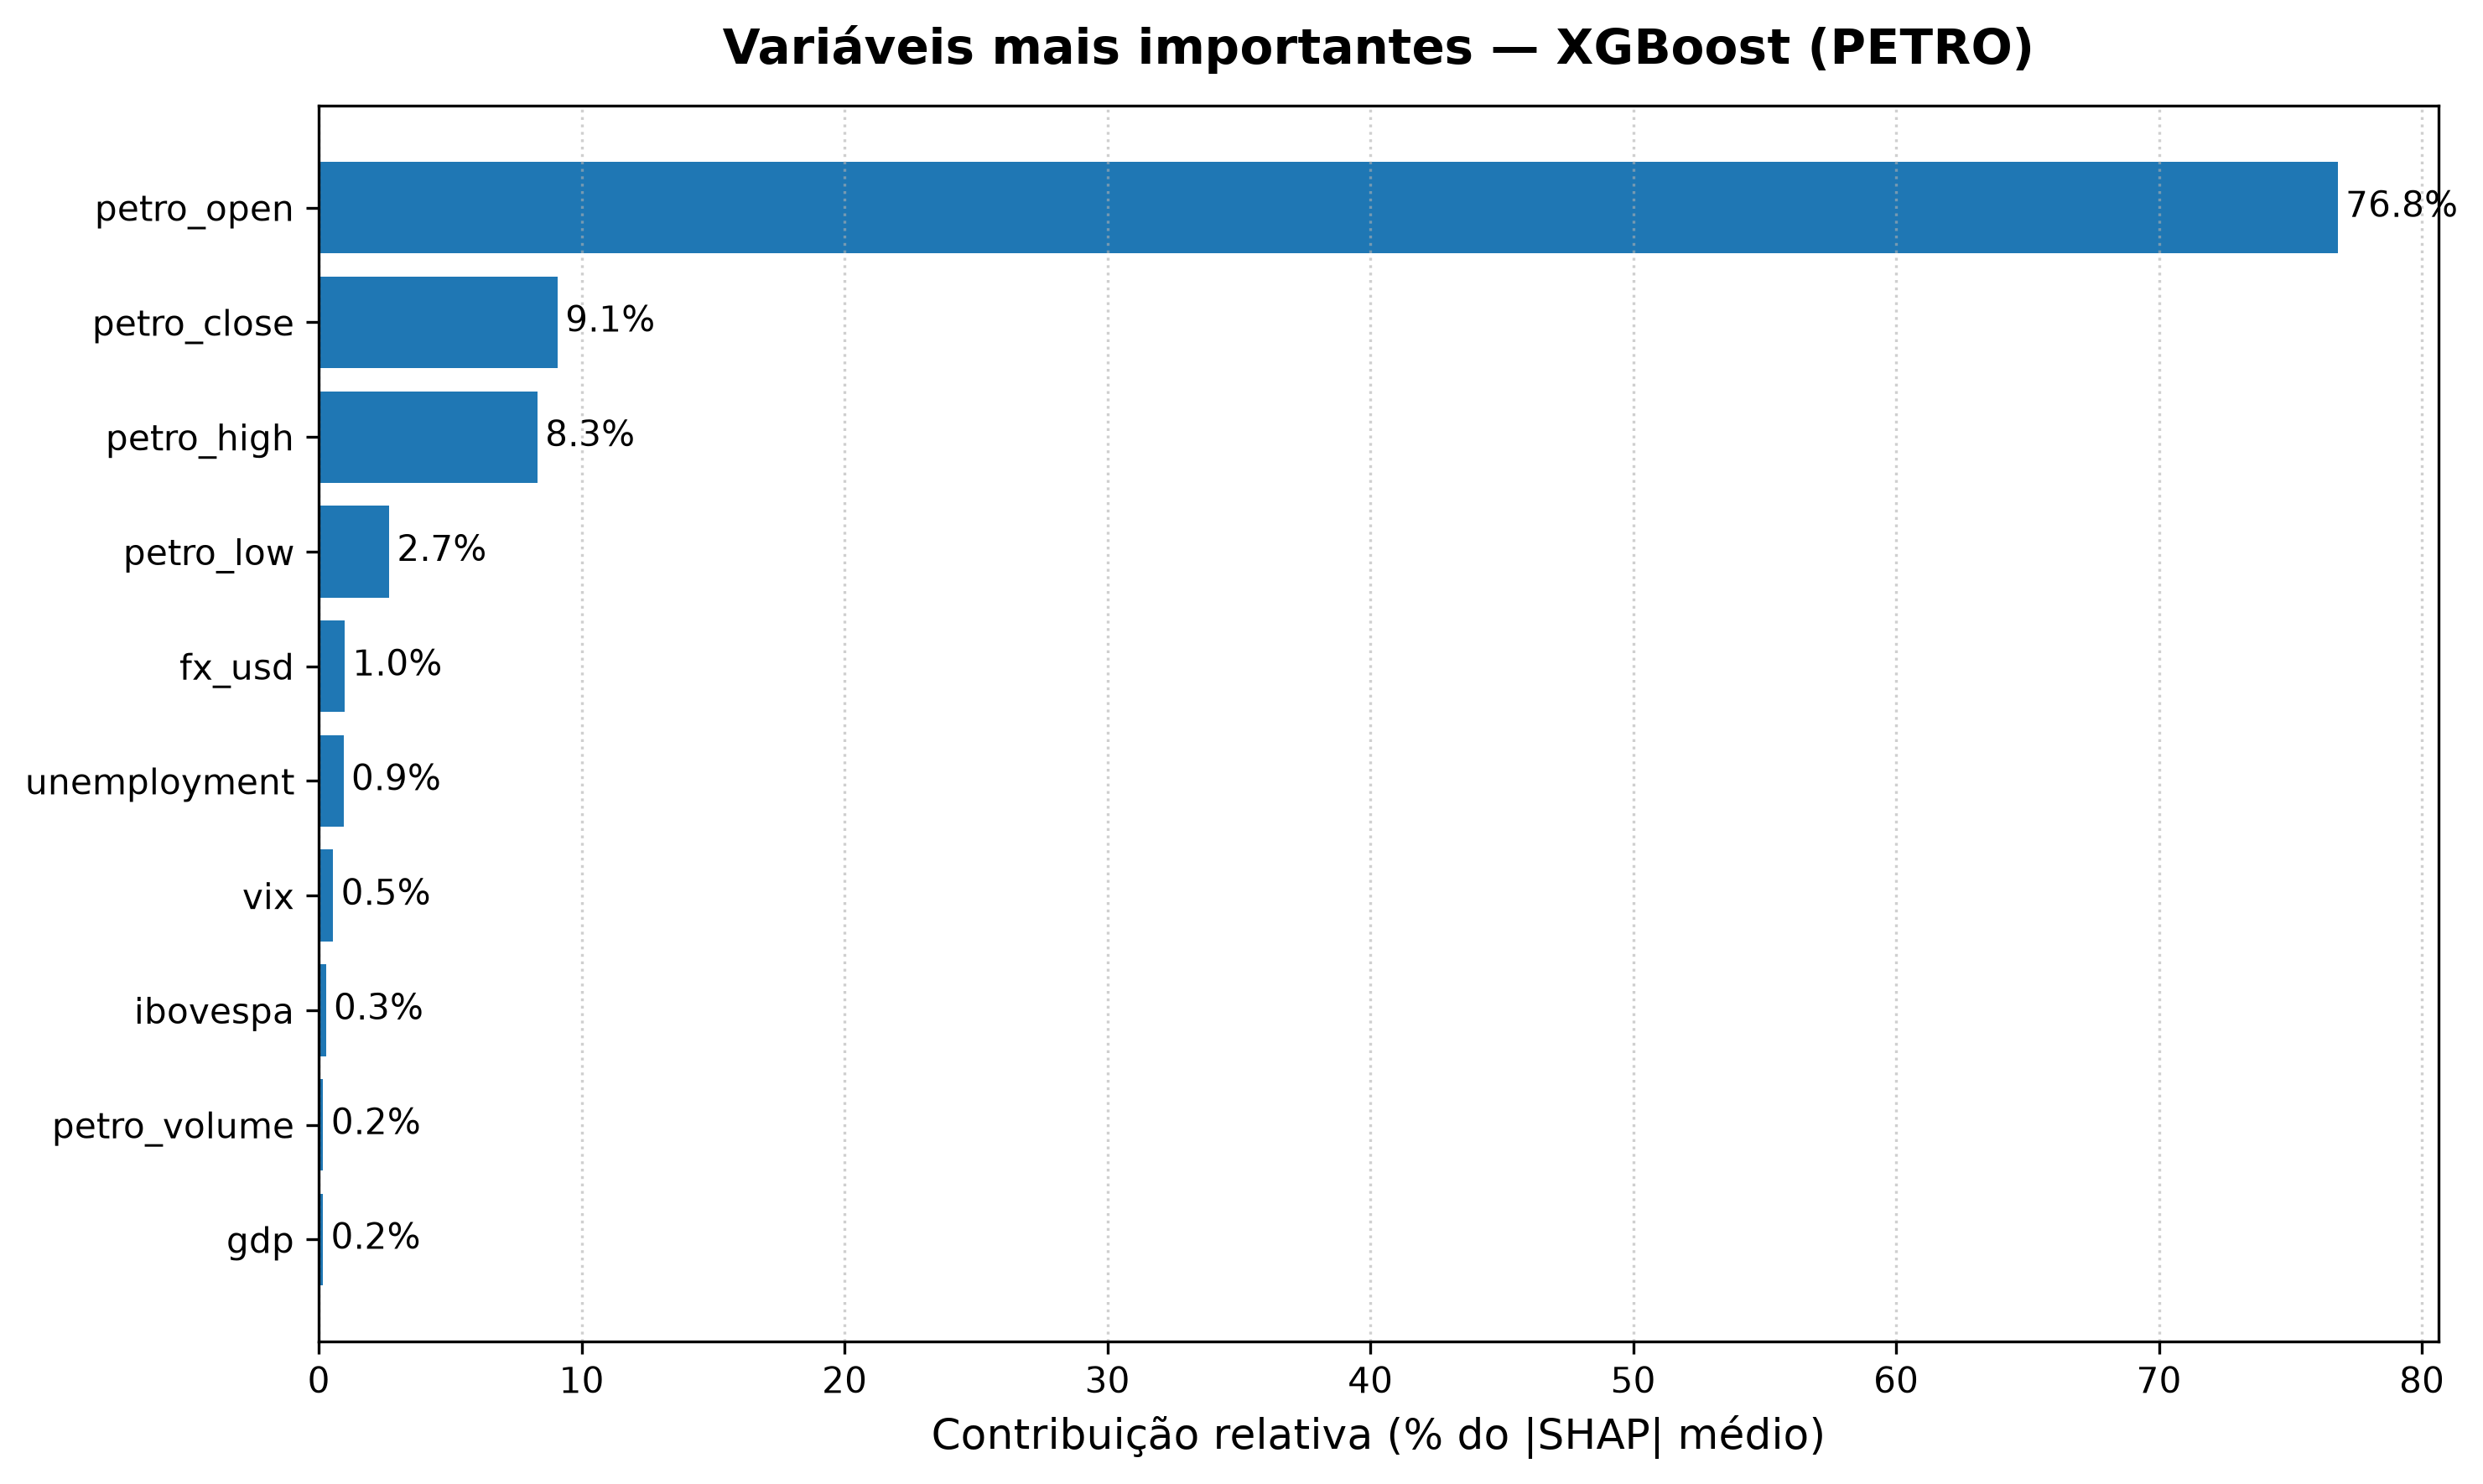

,variavel,mean_abs_shap,pct
0,petro_open,8.581964,76.796883
1,petro_close,1.014772,9.080830
2,petro_high,0.928935,8.312705
3,petro_low,0.298624,2.672280
4,fx_usd,0.109746,0.982076
5,unemployment,0.104796,0.937782
6,vix,0.061040,0.546222
7,ibovespa,0.030097,0.269324
8,petro_volume,0.018807,0.168300
9,gdp,0.017868,0.159894


In [ ]:
tab_petro = explain_variables(res_xgbooster)
tab_petro.head(10)

In [ ]:
tab_petro = explain_variables(res_lstm)
tab_petro.head(10)